In [ ]:
# cumc


from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
from femr.models.tokenizer.clmbr_tokenizer import CLMBRTokenizer
import pickle as pl
from pathlib import Path

cumc_lab_codes = ["LOINC/26515-7//UCUM/10*9/L","LOINC/2160-0//UCUM/mg/dL",\
"LOINC/1968-7//UCUM/mg/dL","LOINC/2708-6//UCUM/%"]

# tpp_task_path =
ntp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/ntp/ntp_task.pkl"
tpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/tpp/tpp_task.pkl"
mtpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/mtpp/mtpp_task.pkl"

cumc_ontology_path = "/data2/processed_datasets/zj2398/femr/cumc/mtpp/ontology.pkl"

def check_code(base_dir,model_name, lab_codes,ontology_path,model_task_path):
    with open(model_task_path,"rb") as f:
        model_task = pl.load(f)
    with open(ontology_path, 'rb') as f:
        ontology = pl.load(f)
    tokenizer_path =base_dir/model_name/"tokenizer"
    if model_name != "ntp":
        tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
        tokenizer_vocab = [ i["code_string"] for i in tokenizer.dictionary["vocab"] if i["type"] == "code"]
    else:
        tokenizer = CLMBRTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
        tokenizer_vocab = [ i["code_string"] for i in tokenizer.dictionary["vocab"] if i["type"] == "code"]
        pretraining_task = list(tokenizer.original_code_to_id.keys())
    print(len(tokenizer_vocab),tokenizer_vocab)
    for code in lab_codes:
        if code in tokenizer_vocab:
            print(f"code {code} in {model_name} tokenizer")
        if model_name == "mtpp":
            if (code in model_task.task_to_index_map.keys() or code in model_task.numerical_task_to_index_map.keys()):
                print(f"code {code} in pretraining task of {model_name}")
        elif model_name == "ntp":
            if code in pretraining_task:
                print(f"code {code} in pretraining task of {model_name}")
        else:
            if code in model_task.task_to_index_map.keys():
                print(f"code {code} in pretraining task of {model_name}")
    print()



# for model in ["tpp","mtpp"]:
cumc_base_dir = Path("/data2/processed_datasets/zj2398/femr/cumc")
check_code(cumc_base_dir,"mtpp",cumc_lab_codes,cumc_ontology_path,mtpp_task_path)
check_code(cumc_base_dir,"tpp",cumc_lab_codes,cumc_ontology_path,tpp_task_path)
check_code(cumc_base_dir,"ntp",cumc_lab_codes,cumc_ontology_path,ntp_task_path)

# print(len(mtpp_tokenizer.dictionary["vocab"]))
# print(mtpp_task.numerical_time_bins.shape)
# # print(mtpp_task.non_numerical_time_bins.shape)
# print(len(motor_task.pretraining_task_info))
# # print(tpp_task.time_bins.shape)




7532 ['MEDS_BIRTH', 'CPT4/1002795', 'Gender/F', 'Gender/M', 'Visit/OP', 'SNOMED/71388002', 'PCORNet/Generic-NI', 'Race/Unknown', 'Visit/OMOP4822459', 'RxNorm/1151131', 'ATC/A', 'LOINC/786-4//UCUM/g/dL', 'LOINC/718-7//UCUM/g/dL', 'ATC/C', 'ATC/B', 'ATC/G', 'LOINC/8462-4//UCUM/mm[Hg]', 'LOINC/8480-6//UCUM/mm[Hg]', 'ATC/J', 'ATC/S', 'RxNorm/1151133', 'ATC/N', 'LOINC/787-2//UCUM/fL', 'LOINC/785-6//UCUM/pg', 'LOINC/788-0//UCUM/%', 'ATC/D', 'ATC/R', 'LOINC/6690-2//UCUM/10*9/L', 'ATC/M', 'LOINC/2345-7//UCUM/mg/dL', 'Ethnicity/Unknown', 'LOINC/2160-0//UCUM/mg/dL', 'LOINC/2951-2//UCUM/mmol/L', 'LOINC/2823-3//UCUM/mmol/L', 'LOINC/789-8//UCUM/10*12/L', 'SNOMED/404684003', 'LOINC/29463-7//UCUM/[oz_av]', 'LOINC/3094-0//UCUM/mg/dL', 'LOINC/8867-4//UCUM//min', 'LOINC/20570-8//UCUM/%', 'RxNorm/1151126', 'LOINC/2075-0//UCUM/mmol/L', 'LOINC/17861-6//UCUM/mg/dL', 'LOINC/706-2//UCUM/%', 'LOINC/8302-2//UCUM/[in_us]', 'LOINC/2028-9//UCUM/mmol/L', 'ATC/P', 'LOINC/8310-5//UCUM/[degF]', 'LOINC/63503-7', 'Visit

In [1]:
# cumc
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
from femr.models.tokenizer.clmbr_tokenizer import CLMBRTokenizer
import pickle as pl
from pathlib import Path

mimic_lab_codes = ["LAB//51265//K/uL","LAB//50885//mg/dL","LAB//50912//mg/dL","LAB//50821//mm Hg"]

# tpp_task_path =
ntp_task_path = "/user/zj2398/cache/ntp/ntp_task.pkl"
tpp_task_path = "/user/zj2398/cache/tpp/tpp_task.pkl"
mtpp_task_path = "/user/zj2398/cache/mtpp/mtpp_task.pkl"

mimic_ontology_path = "/user/zj2398/cache/tpp/ontology.pkl"

def check_code(base_dir,model_name, lab_codes,ontology_path,model_task_path):
    with open(model_task_path,"rb") as f:
        model_task = pl.load(f)
    with open(ontology_path, 'rb') as f:
        ontology = pl.load(f)
    tokenizer_path =base_dir/model_name/"tokenizer"
    if model_name != "ntp":
        tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
        tokenizer_vocab = [ i["code_string"] for i in tokenizer.dictionary["vocab"] if i["type"] == "code"]
    else:
        tokenizer = CLMBRTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
        tokenizer_vocab = [ i["code_string"] for i in tokenizer.dictionary["vocab"] if i["type"] == "code"]
        pretraining_task = list(tokenizer.original_code_to_id.keys())
    print(len(tokenizer_vocab),tokenizer_vocab)
    for code in lab_codes:
        if code in tokenizer_vocab:
            print(f"code {code} in {model_name} tokenizer")
        if model_name == "mtpp":
            if (code in model_task.task_to_index_map.keys() or code in model_task.numerical_task_to_index_map.keys()):
                print(f"code {code} in pretraining task of {model_name}")
        elif model_name == "ntp":
            if code in pretraining_task:
                print(f"code {code} in pretraining task of {model_name}")
        else:
            if code in model_task.task_to_index_map.keys():
                print(f"code {code} in pretraining task of {model_name}")
    print()



# for model in ["tpp","mtpp"]:
mimic_base_dir = Path("/user/zj2398/cache")
check_code(mimic_base_dir,"mtpp",mimic_lab_codes,mimic_ontology_path,mtpp_task_path)
check_code(mimic_base_dir,"tpp",mimic_lab_codes,mimic_ontology_path,tpp_task_path)
check_code(mimic_base_dir,"ntp",mimic_lab_codes,mimic_ontology_path,ntp_task_path)

# print(len(mtpp_tokenizer.dictionary["vocab"]))
# print(mtpp_task.numerical_time_bins.shape)
# # print(mtpp_task.non_numerical_time_bins.shape)
# print(len(motor_task.pretraining_task_info))
# # print(tpp_task.time_bins.shape)




/user/zj2398/.conda/envs/tte/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


8390 ['MEDS_BIRTH', 'ED_OUT', 'ED_REGISTRATION', 'LAB//51516//#/hpf', 'LAB//51493//#/hpf', 'LAB//51476//#/hpf', 'MEDICATION//STOP//Sodium Chloride 0.9%  Flush', 'MEDICATION//START//Sodium Chloride 0.9%  Flush', 'LAB//50885//mg/dL', 'LAB//52172//fL', 'LAB//51249//g/dL', 'LAB//50863//IU/L', 'LAB//51275//sec', 'LAB//51249//%', 'GENDER//M', 'GENDER//F', 'LAB//50933//UNK', 'MEDICATION//START//Acetaminophen', 'MEDICATION//STOP//Acetaminophen', 'LAB//50887//UNK', 'LAB//51274//sec', 'LAB//51237//UNK', 'Weight (Lbs)', 'Blood Pressure', 'LAB//50862//g/dL', 'LAB//50878//IU/L', 'LAB//51466//UNK', 'LAB//51487//UNK', 'LAB//51508//UNK', 'LAB//51506//UNK', 'LAB//51486//UNK', 'LAB//50970//mg/dL', 'LAB//51464//mg/dL', 'LAB//52075//K/uL', 'LAB//52073//K/uL', 'LAB//52069//K/uL', 'LAB//52074//K/uL', 'LAB//51133//K/uL', 'LAB//51087//UNK', 'LAB//50861//IU/L', 'LAB//50955//UNK', 'LAB//50960//mg/dL', 'MEDICATION//START//UNK', 'MEDICATION//STOP//UNK', 'LAB//51678//UNK', 'LAB//50934//UNK', 'LAB//50947//UNK', 'LA

In [2]:
print(len(mtpp_task.pretraining_task_info))

6100


In [13]:
for code in lab_regression_codes:  
    if code in list(tpp_task.task_to_index_map.keys()):
        print(code,tpp_task.task_to_index_map[code])
    # if code in list(mtpp_task.numerical_task_to_index_map.keys()):
    #     print(code,mtpp_task.numerical_task_to_index_map[code])
    # if code in list(mtpp_task.task_to_index_map.keys()):
    #     print(code,mtpp_task.task_to_index_map[code])

LOINC/26515-7//UCUM/10*9/L 47
LOINC/2160-0//UCUM/mg/dL 27
LOINC/1968-7//UCUM/mg/dL 61
LOINC/2708-6//UCUM/% 58


In [3]:
import pickle as pl
import json
# mtpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/mtpp/mtpp_task.pkl"
# tpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/tpp/tpp_task.pkl"
# motor_json_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/motor_model/config.json"
# with open(tpp_task_path,"rb") as f:
#     tpp_task = pl.load(f)
# with open(mtpp_task_path,"rb") as f:
#     mtpp_task = pl.load(f)
# with open (motor_json_path,"r") as file:
#     motor_json = json.load(file)
# print(len(motor_json["task_config"]["task_kwargs"]["pretraining_task_info"]))
# print(len(tpp_task.pretraining_task_info))

mtpp_task_path = "/user/zj2398/cache/mtpp_8k_T_16_V_5/mtpp_task.pkl"
# mtpp_task_path = "/user/zj2398/cache/mtpp_8k_num_bin5/mtpp_task.pkl"
# mtpp_task_path = "/shared/share_mala/zj2398/models/mtpp_8k/mtpp_all_shared_6100_bin_5/mtpp_task.pkl"
# tpp_task_path = "/shared/share_mala/zj2398/models/tpp_8k/tpp_task.pkl"
# motor_task_path = "/shared/share_mala/zj2398/models/motor_8k/motor_task.pkl"
# with open(tpp_task_path,"rb") as f:
#     tpp_task = pl.load(f)
with open(mtpp_task_path,"rb") as f:
    mtpp_task = pl.load(f)
# with open (motor_task_path,"rb") as f:
#     motor_task = pl.load(f)
# print(len(motor_json["task_config"]["task_kwargs"]["pretraining_task_info"]))
# print(len(motor_task.pretraining_task_info))
# print(len(tpp_task.pretraining_task_info))
print(mtpp_task.non_numerical_time_bins.shape)
print(mtpp_task.numerical_time_bins.shape)
print(mtpp_task.num_value_bins)
# print(motor_task.non_numerical_time_bins.shape)
# print(motor_task.numerical_time_bins.shape)
# print(len(motor_task.pretraining_task_codes))

# old
# (5882, 9)
# (1164, 9)
# 5

# new
# (4936, 9)
# (1164, 9)
# 5


(4936, 17)
(1164, 17)
5


In [6]:
from collections import Counter
def task_counter(task_list):
    # print(task_list)
    type_list = [i.split("/")[0] for i in task_list]
    counter_list = Counter(type_list)
    return counter_list
tpp_counter = task_counter(list(tpp_task.task_to_index_map.keys()))
mtpp_list = [i[0] for i in motor_json["task_config"]["task_kwargs"]["pretraining_task_info"]]
mtpp_counter = task_counter(mtpp_list)
print(tpp_counter)
print(mtpp_counter)

Counter({'ICD10CM': 1895, 'ATC': 1572, 'RxNorm': 1091, 'SNOMED': 999, 'LOINC': 761, 'CPT4': 363, 'ICD10PCS': 124, 'CVX': 65, 'ICD9CM': 30, 'HCPCS': 19, 'ISBT Attribute': 10, 'NUCC': 8, 'NDC': 8, 'Visit': 7, 'CMS Place of Service': 7, 'OMOP Extension': 4, 'RxNorm Extension': 3, 'PCORNet': 1, 'Domain': 1, 'MEDS_DEATH': 1, 'PPI': 1, 'Medicare Specialty': 1, 'ICD9Proc': 1})
Counter({'ICD10CM': 1895, 'ATC': 1572, 'RxNorm': 1091, 'SNOMED': 999, 'LOINC': 761, 'CPT4': 363, 'ICD10PCS': 124, 'CVX': 65, 'ICD9CM': 30, 'HCPCS': 19, 'ISBT Attribute': 10, 'NUCC': 8, 'NDC': 8, 'Visit': 7, 'CMS Place of Service': 7, 'OMOP Extension': 4, 'RxNorm Extension': 3, 'PCORNet': 1, 'Domain': 1, 'MEDS_DEATH': 1, 'PPI': 1, 'Medicare Specialty': 1, 'ICD9Proc': 1})


In [3]:
tpp_list = list(tpp_task.task_to_index_map.keys())
mtpp_list = list(mtpp_task.task_to_index_map.keys())
tpp_set = set(tpp_list)
mtpp_set = set(mtpp_list)
unique_tpp = tpp_set - mtpp_set
print(len(unique_tpp))
print(unique_tpp)

mtpp_num_set = set(mtpp_task.numerical_task_to_index_map.keys())
print(unique_tpp-mtpp_num_set)
mtpp_num_unique = mtpp_num_set-unique_tpp
print(len(mtpp_num_unique),mtpp_num_unique)

301
{'LOINC/89278-6//SNOMED/258983007', 'LOINC/60517-0//UCUM/%', 'LOINC/13969-1//UCUM/ng/mL', 'LOINC/29609-5//UCUM/[iU]/mL', 'LOINC/2890-2//UCUM/mg/mg{creat}', 'LOINC/6098-8//UCUM/10*3.[iU]/L', 'LOINC/2777-1//UCUM/mg/dL', 'LOINC/3094-0//UCUM/mg/dL', 'LOINC/28649-2//UCUM/mm[Hg]', 'LOINC/5820-6//UCUM//[LPF]', 'LOINC/2162-6//UCUM/mg/(24.h)', 'LOINC/1925-7//UCUM/mmol/L', 'LOINC/789-8//UCUM/10*12/L', 'LOINC/7155-5//UCUM/10*3.[iU]/L', 'LOINC/2157-6//UCUM/[iU]/L', 'LOINC/5643-2//UCUM/mg/dL', 'LOINC/8867-4//UCUM//min', 'LOINC/73831-0//None/No matching concept', 'LOINC/13457-7//UCUM/mg/dL', 'LOINC/2132-9//UCUM/ng/L', 'LOINC/10535-3//UCUM/ng/mL', 'LOINC/2839-9//UCUM/ng/mL', 'LOINC/2284-8//UCUM/ng/mL', 'LOINC/1649-3//UCUM/ng/L', 'LOINC/6298-4//UCUM/mmol/L', 'LOINC/10900-9//UCUM/10*-3.[iU]/mL', 'LOINC/2711-0//UCUM/%', 'LOINC/29604-6//UCUM/[iU]/mL', 'LOINC/46216-8//UCUM/[iU]/mL', 'LOINC/3026-2//UCUM/ug/dL', 'LOINC/8099-4//UCUM/[iU]/mL', 'LOINC/30934-4//UCUM/ng/L', 'LOINC/26478-8//UCUM/%', 'LOINC/12

In [9]:
'''
include in tpp: 'LOINC/1747-5//UCUM/g/dL', 'LOINC/6298-4//UCUM/mmol/L', 'LOINC/89280-2//UCUM/mm[Hg]', 'LOINC/5763-8//UCUM/ug/dL'
not included: 'LOINC/71695-1//UCUM/%', 'LOINC/13964-2//UCUM/umol/L', 'LOINC/52770-5//UCUM/s', 'LOINC/2963-7//UCUM/ng/mL', 'LOINC/53019-6//UCUM/[iU]/mL', 'LOINC/25489-6//UCUM/nmol/L', 'LOINC/21394-2//UCUM/%', 'LOINC/68518-0//None/No matching concept', 'LOINC/18262-6//UCUM/mg/dL', 'LOINC/44254-1', 'LOINC/783-1//UCUM/%', 'LOINC/1547-9//UCUM/mg/dL', 'LOINC/88122-7', 'LOINC/99106-7//None/No matching concept', 'LOINC/LA48-4//None/No matching concept', 'LOINC/33037-3//UCUM/mmol/L', 'LOINC/98979-8//UCUM/mL/min/1.73.m2'
'''

import meds_reader
unique_tpp_dict = {code:[0,0,0] for code in unique_tpp}
meds_reader_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader"
cumc_meds = meds_reader.SubjectDatabase(meds_reader_path)
for subject_id in cumc_meds:
    subject = cumc_meds[subject_id]
    for event in subject.events:
        if event.code in unique_tpp:
            # if event.numeric_value:
                # numerical
            if event.numeric_value is not None:
                unique_tpp_dict[event.code][1] += 1
            # only textual
            elif event.numeric_value is None and event.text_value is not None:
                unique_tpp_dict[event.code][2] += 1
            # missing value
            else:
                unique_tpp_dict[event.code][0] += 1
print(unique_tpp_dict)

        # for k,v in event:
            # if isinstance(v,str) and v.split("/")[0] == "SPL":
            #     print(event,k,v)

{'LOINC/89278-6//SNOMED/258983007': [552, 2492105, 0], 'LOINC/60517-0//UCUM/%': [115, 7277, 0], 'LOINC/13969-1//UCUM/ng/mL': [150, 6731, 1], 'LOINC/29609-5//UCUM/[iU]/mL': [1127, 3177, 799], 'LOINC/2890-2//UCUM/mg/mg{creat}': [366, 4974, 0], 'LOINC/6098-8//UCUM/10*3.[iU]/L': [270, 1056, 6], 'LOINC/2777-1//UCUM/mg/dL': [7275, 742074, 13], 'LOINC/3094-0//UCUM/mg/dL': [13274, 2066256, 30], 'LOINC/28649-2//UCUM/mm[Hg]': [393, 8699, 1], 'LOINC/5820-6//UCUM//[LPF]': [996, 62, 0], 'LOINC/2162-6//UCUM/mg/(24.h)': [1217, 7836, 0], 'LOINC/1925-7//UCUM/mmol/L': [7432, 275122, 4], 'LOINC/789-8//UCUM/10*12/L': [2291, 1924910, 21], 'LOINC/7155-5//UCUM/10*3.[iU]/L': [180, 921, 11], 'LOINC/2157-6//UCUM/[iU]/L': [935, 128529, 10], 'LOINC/5643-2//UCUM/mg/dL': [6186, 5319, 0], 'LOINC/8867-4//UCUM//min': [11003, 8816893, 0], 'LOINC/73831-0//None/No matching concept': [1264, 66146, 0], 'LOINC/13457-7//UCUM/mg/dL': [1341, 145439, 2], 'LOINC/2132-9//UCUM/ng/L': [1106, 70313, 4], 'LOINC/10535-3//UCUM/ng/mL': 

In [4]:

import meds_reader
mtpp_num_dict = {code:[0,0,0] for code in mtpp_num_set}
meds_reader_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader"
cumc_meds = meds_reader.SubjectDatabase(meds_reader_path)
for subject_id in cumc_meds:
    subject = cumc_meds[subject_id]
    for event in subject.events:
        if event.code in mtpp_num_set:
            # if event.numeric_value:
                # numerical
            if event.numeric_value is not None:
                mtpp_num_dict[event.code][1] += 1
            # only textual
            elif event.numeric_value is None and event.text_value is not None:
                mtpp_num_dict[event.code][2] += 1
            # missing value
            else:
                mtpp_num_dict[event.code][0] += 1
print(mtpp_num_dict)

{'LOINC/14196-0//UCUM/10*9/L': [13, 20019, 1], 'LOINC/15048-2//UCUM/%': [6, 6241, 5], 'LOINC/3094-0//UCUM/mg/dL': [13274, 2066256, 30], 'LOINC/12187-1//UCUM/%': [0, 6251, 0], 'LOINC/73831-0//None/No matching concept': [1264, 66146, 0], 'LOINC/13457-7//UCUM/mg/dL': [1341, 145439, 2], 'LOINC/2132-9//UCUM/ng/L': [1106, 70313, 4], 'LOINC/LA18927-6//None/No matching concept': [4, 12593, 0], 'LOINC/10535-3//UCUM/ng/mL': [1241, 21326, 1], 'LOINC/2839-9//UCUM/ng/mL': [336, 5695, 0], 'LOINC/1649-3//UCUM/ng/L': [1035, 7926, 0], 'LOINC/29604-6//UCUM/[iU]/mL': [7682, 3026, 12027], 'LOINC/6874-2//UCUM/mg/(24.h)': [46, 1609, 0], 'LOINC/44258-2': [0, 20077, 0], 'LOINC/8099-4//UCUM/[iU]/mL': [1674, 7524, 1], 'LOINC/18261-8//UCUM/mg/dL': [17709, 279340, 0], 'LOINC/12841-3//UCUM/%': [263, 4918, 0], 'LOINC/26487-9//UCUM/%': [30, 11943, 0], 'LOINC/2923-1//UCUM/mg/L': [24, 4974, 0], 'LOINC/28542-9//UCUM/fL': [39754, 1264461, 0], 'LOINC/765-8//UCUM/%': [2, 2827, 0], 'LOINC/5787-7//UCUM//[HPF]': [2004, 96, 0

In [10]:
for i in mtpp_num_dict:
    if mtpp_num_dict[i][2] > 0.5*max(mtpp_num_dict[i][0],mtpp_num_dict[i][1]):
        print(i,mtpp_num_dict[i])
print()
for i in unique_tpp_dict:
    if unique_tpp_dict[i][2] > 0.5*max(unique_tpp_dict[i][0],unique_tpp_dict[i][1]):
        print(i,unique_tpp_dict[i])

LOINC/29604-6//UCUM/[iU]/mL [7682, 3026, 12027]
LOINC/36923-1//UCUM/[iU]/mL [4252, 1233, 3047]
LOINC/42595-9//UCUM/[iU]/mL [883, 454, 555]
LOINC/25145-4//UCUM//[HPF] [19689, 4, 30173]
LOINC/5804-0//UCUM/mg/dL [140, 40199, 160291]
LOINC/13653-1//UCUM//[LPF] [1596, 794, 1500]
LOINC/31161-3//UCUM/10*3.[iU]/L [643, 77, 600]
LOINC/11277-1//UCUM//[LPF] [47804, 4022, 52753]
LOINC/5797-6//UCUM/mg/dL [456, 12656, 172293]
LOINC/50231-0//UCUM//[LPF] [2127, 112, 1584]
LOINC/5792-7//UCUM/mg/dL [770, 14743, 186512]

LOINC/29604-6//UCUM/[iU]/mL [7682, 3026, 12027]
LOINC/36923-1//UCUM/[iU]/mL [4252, 1233, 3047]
LOINC/5822-2//UCUM//[HPF] [3539, 2, 1971]
LOINC/42595-9//UCUM/[iU]/mL [883, 454, 555]
LOINC/13653-1//UCUM//[LPF] [1596, 794, 1500]
LOINC/11277-1//UCUM//[LPF] [47804, 4022, 52753]
LOINC/25145-4//UCUM//[HPF] [19689, 4, 30173]
LOINC/50231-0//UCUM//[LPF] [2127, 112, 1584]
LOINC/5792-7//UCUM/mg/dL [770, 14743, 186512]
LOINC/31161-3//UCUM/10*3.[iU]/L [643, 77, 600]


In [3]:
# full cumc
import pickle as pl
motor_task_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/motor_task.pkl"
tpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/tpp/tpp_task.pkl"
with open(tpp_task_path,"rb") as f:
    tpp_task = pl.load(f)
with open(motor_task_path,"rb") as f:
    motor_task = pl.load(f)
print(len(motor_task.pretraining_task_info))
print(len(tpp_task.pretraining_task_info))

FileNotFoundError: [Errno 2] No such file or directory: '/data2/processed_datasets/zj2398/femr/cumc/tpp/tpp_task.pkl'

In [15]:
import pickle
parent_dict = {}
ontology_path = "/data2/processed_datasets/zj2398/femr/cumc_0.1/tpp/ontology.pkl"
with open(ontology_path, 'rb') as f:
    ontology = pickle.load(f)
for i in mtpp_num_dict:
    parent_dict[i] = ontology.get_all_parents(i) - {i}
    if len(parent_dict[i]) > 0:
        print(i,parent_dict[i])

In [1]:
# mimic
import pickle as pl
tpp_task_path = "/shared/share_mala/zj2398/models/tpp_8k/tpp_task.pkl"
mtpp_task_path = "/user/zj2398/cache/mtpp_8k/mtpp_task.pkl"
motor_task_path = "/shared/share_mala/zj2398/models/motor_8k/motor_task.pkl"
with open(motor_task_path,"rb") as f:
    motor_task = pl.load(f)
with open(tpp_task_path,"rb") as f:
    tpp_task = pl.load(f)
with open(mtpp_task_path,"rb") as f:
    mtpp_task = pl.load(f)
print(mtpp_task.numerical_time_bins.shape)
print(mtpp_task.non_numerical_time_bins.shape)
# print(len(motor_task.time_bins))
# print(tpp_task.time_bins.shape)

FileNotFoundError: [Errno 2] No such file or directory: '/shared/share_mala/zj2398/models/motor_8k/motor_task.pkl'

In [1]:
import pickle as pl
mtpp_task_path = "/data2/processed_datasets/zj2398/femr/mimic/mtpp/mtpp_task.pkl"
with open(mtpp_task_path,"rb") as f:
    mtpp_task = pl.load(f)
print(mtpp_task.numerical_time_bins.shape)
print(mtpp_task.non_numerical_time_bins.shape)

/data/anaconda3/envs/motor_chao/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(1164, 9)
(4936, 9)


In [3]:
print(len(motor_task.pretraining_task_info))
print(tpp_task.time_bins.shape)

6100
(6100, 9)


In [ ]:
# print(mtpp_task.numerical_time_bins.shape)
# print(mtpp_task.non_numerical_time_bins.shape)
# mtpp_list = list(mtpp_task.task_to_index_map.keys())
# print(mtpp_list)
for i in mtpp_task.pretraining_task_info:
    if i[0].split("/")[0] == "LOINC":
        print(i)

('LOINC/786-4//UCUM/g/dL', 1.083955342713655e-08, 2015828, 5189049, 66443088.29590829)
('LOINC/718-7//UCUM/g/dL', 1.0705592155972083e-08, 2037043, 5167834, 66999458.01520837)
('LOINC/8462-4//UCUM/mm[Hg]', 6.7501232653905875e-09, 1933496, 5271381, 108389230.28524002)
('LOINC/8480-6//UCUM/mm[Hg]', 6.750605037782318e-09, 1933335, 5271542, 108384805.05761547)
('LOINC/787-2//UCUM/fL', 9.746913564665471e-09, 2132260, 5072617, 72233454.81957358)
('LOINC/785-6//UCUM/pg', 9.746472062743812e-09, 2132326, 5072551, 72235787.02216326)
('LOINC/788-0//UCUM/%', 9.72641589289215e-09, 2136358, 5068519, 72327203.25288323)
('LOINC/6690-2//UCUM/10*9/L', 9.457163616865955e-09, 2246703, 4958174, 72766969.74323538)
('LOINC/2345-7//UCUM/mg/dL', 8.95189536653627e-09, 2231151, 4973726, 77115253.0710146)
('LOINC/2160-0//UCUM/mg/dL', 8.86748231028056e-09, 2240963, 4963914, 77695764.95765655)
('LOINC/2951-2//UCUM/mmol/L', 8.839886746200359e-09, 2249074, 4955803, 77810957.9755869)
('LOINC/2823-3//UCUM/mmol/L', 8.821

: 

In [15]:
tpp_set = set(tpp_list)
mtpp_set = set(mtpp_list)
unique_tpp = tpp_set - mtpp_set
print(unique_tpp)
mtpp_num_set = set(mtpp_task.numerical_task_to_index_map.keys())
print(len(tpp_set-mtpp_set))
print((tpp_set-mtpp_set)-mtpp_num_set)

{'LOINC/14334-7//UCUM/mmol/L', 'LOINC/10535-3//UCUM/ng/mL', 'LOINC/5905-5//UCUM/%', 'LOINC/2078-4//UCUM/mmol/L', 'LOINC/22735-5//UCUM/mmol/L', 'LOINC/789-8//UCUM/10*12/L', 'LOINC/11277-1//UCUM//[LPF]', 'LOINC/59032-3//UCUM/mmol/L', 'LOINC/10839-9//UCUM/ng/mL', 'LOINC/38253-1//UCUM/mm[Hg]', 'LOINC/13058-3//UCUM/s', 'LOINC/20454-5//UCUM/mg/dL', 'LOINC/4633-4//UCUM/%', 'LOINC/2342-4//UCUM/mg/dL', 'LOINC/6095-4//UCUM/10*3.[iU]/L', 'LOINC/3255-7//UCUM/mg/dL', 'LOINC/6273-7//UCUM/10*3.[iU]/L', 'LOINC/48642-3//UCUM/mL/min/1.73.m2', 'LOINC/36923-1//UCUM/[iU]/mL', 'LOINC/2039-6//UCUM/ng/mL', 'LOINC/3084-1//UCUM/mg/dL', 'LOINC/2839-9//UCUM/ng/mL', 'LOINC/22763-7//UCUM/um/L', 'LOINC/19161-9//UCUM/mg/dL', 'LOINC/6298-4//UCUM/mmol/L', 'LOINC/8626-4//UCUM/deg', 'LOINC/6690-2//UCUM/10*9/L', 'LOINC/2028-9//UCUM/mmol/L', 'LOINC/26449-9//UCUM/10*9/L', 'LOINC/706-2//UCUM/%', 'LOINC/1763-2//UCUM/ng/dL', 'LOINC/14959-1//UCUM/ug/mg', 'LOINC/1747-5//UCUM/g/dL', 'LOINC/2336-6//UCUM/g/dL', 'LOINC/73831-0//None

In [7]:
import pickle
ontology_path = "/data2/processed_datasets/zj2398/femr/ontology.pkl"
with open(ontology_path, 'rb') as f:
    ontology = pickle.load(f)
print(ontology)

In [13]:
import polars as pl
code_metadata_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader/metadata/codes.parquet"
code_metadata = pl.scan_parquet(code_metadata_path)
code_metadata_items = (
    code_metadata.select(pl.col("code")).collect().to_dicts()
)
# print(code_metadata_items)
# for code_info in code_metadata_items:
#     print(code_info)

In [9]:
import pandas as pd
code_metadata2 = pd.read_parquet(code_metadata_path)
print(code_metadata2)
for i in code_metadata2["code"]:
    # print(i.split("/")[0])
    if i.split("/")[0] == "SPL":
        print(i)

                   code
0          ICD9CM/173.3
1         ICD9CM/786.51
2         ICD9CM/V72.85
3         ICD9CM/786.59
4         ICD9CM/250.00
...                 ...
78966  ICD10CM/S12.041G
78967  ICD10PCS/01S30ZZ
78968  ICD10PCS/0K8V0ZZ
78969     ICD10CM/M54.4
78970  ICD10PCS/0SPB0EZ

[78971 rows x 1 columns]


In [8]:
import pickle as pl
task_path = "/data/models/zj2398/femr/cumc_0.1/mtpp_shared/mtpp_task.pkl"
with open(task_path,"rb") as f:
    mtpp_task = pl.load(f)
print(mtpp_task.numerical_time_bins.shape)
print(mtpp_task.non_numerical_time_bins.shape)
print(len(mtpp_task.numerical_task_to_index_map.keys()),mtpp_task.numerical_task_to_index_map.keys())
print(len(mtpp_task.task_to_index_map.keys()))

(1000, 9)
(8090, 9)
1000 dict_keys(['LOINC/786-4//UCUM/g/dL', 'LOINC/718-7//UCUM/g/dL', 'LOINC/8462-4//UCUM/mm[Hg]', 'LOINC/8480-6//UCUM/mm[Hg]', 'LOINC/787-2//UCUM/fL', 'LOINC/785-6//UCUM/pg', 'LOINC/788-0//UCUM/%', 'LOINC/6690-2//UCUM/10*9/L', 'LOINC/2345-7//UCUM/mg/dL', 'LOINC/2160-0//UCUM/mg/dL', 'LOINC/2951-2//UCUM/mmol/L', 'LOINC/2823-3//UCUM/mmol/L', 'LOINC/789-8//UCUM/10*12/L', 'LOINC/29463-7//UCUM/[oz_av]', 'LOINC/3094-0//UCUM/mg/dL', 'LOINC/8867-4//UCUM//min', 'LOINC/20570-8//UCUM/%', 'LOINC/2075-0//UCUM/mmol/L', 'LOINC/17861-6//UCUM/mg/dL', 'LOINC/8302-2//UCUM/[in_us]', 'LOINC/706-2//UCUM/%', 'LOINC/2028-9//UCUM/mmol/L', 'LOINC/8310-5//UCUM/[degF]', 'LOINC/39156-5//UCUM/kg/m2', 'LOINC/1920-8//UCUM/[iU]/L', 'LOINC/5905-5//UCUM/%', 'LOINC/26515-7//UCUM/10*9/L', 'LOINC/28542-9//UCUM/fL', 'LOINC/1975-2//UCUM/mg/dL', 'LOINC/1742-6//UCUM/[iU]/L', 'LOINC/6768-6//UCUM/[iU]/L', 'LOINC/9279-1//UCUM//min', 'LOINC/1751-7//UCUM/g/dL', 'LOINC/2885-2//UCUM/g/dL', 'LOINC/8277-6//UCUM/m2', '

['LOINC/786-4//UCUM/g/dL', 'LOINC/718-7//UCUM/g/dL', 'LOINC/8462-4//UCUM/mm[Hg]', 'LOINC/8480-6//UCUM/mm[Hg]', 'LOINC/787-2//UCUM/fL', 'LOINC/785-6//UCUM/pg', 'LOINC/788-0//UCUM/%', 'LOINC/6690-2//UCUM/10*9/L', 'LOINC/2345-7//UCUM/mg/dL', 'LOINC/2160-0//UCUM/mg/dL', 'LOINC/2951-2//UCUM/mmol/L', 'LOINC/2823-3//UCUM/mmol/L', 'LOINC/789-8//UCUM/10*12/L', 'LOINC/29463-7//UCUM/[oz_av]', 'LOINC/3094-0//UCUM/mg/dL', 'LOINC/8867-4//UCUM//min', 'LOINC/20570-8//UCUM/%', 'LOINC/2075-0//UCUM/mmol/L', 'LOINC/17861-6//UCUM/mg/dL', 'LOINC/8302-2//UCUM/[in_us]', 'LOINC/706-2//UCUM/%', 'LOINC/2028-9//UCUM/mmol/L', 'LOINC/8310-5//UCUM/[degF]', 'LOINC/39156-5//UCUM/kg/m2', 'LOINC/1920-8//UCUM/[iU]/L', 'LOINC/5905-5//UCUM/%', 'LOINC/26515-7//UCUM/10*9/L', 'LOINC/28542-9//UCUM/fL', 'LOINC/1975-2//UCUM/mg/dL', 'LOINC/1742-6//UCUM/[iU]/L', 'LOINC/6768-6//UCUM/[iU]/L', 'LOINC/9279-1//UCUM//min', 'LOINC/1751-7//UCUM/g/dL', 'LOINC/2885-2//UCUM/g/dL', 'LOINC/8277-6//UCUM/m2', 'LOINC/4544-3//UCUM/%', 'LOINC/2708-

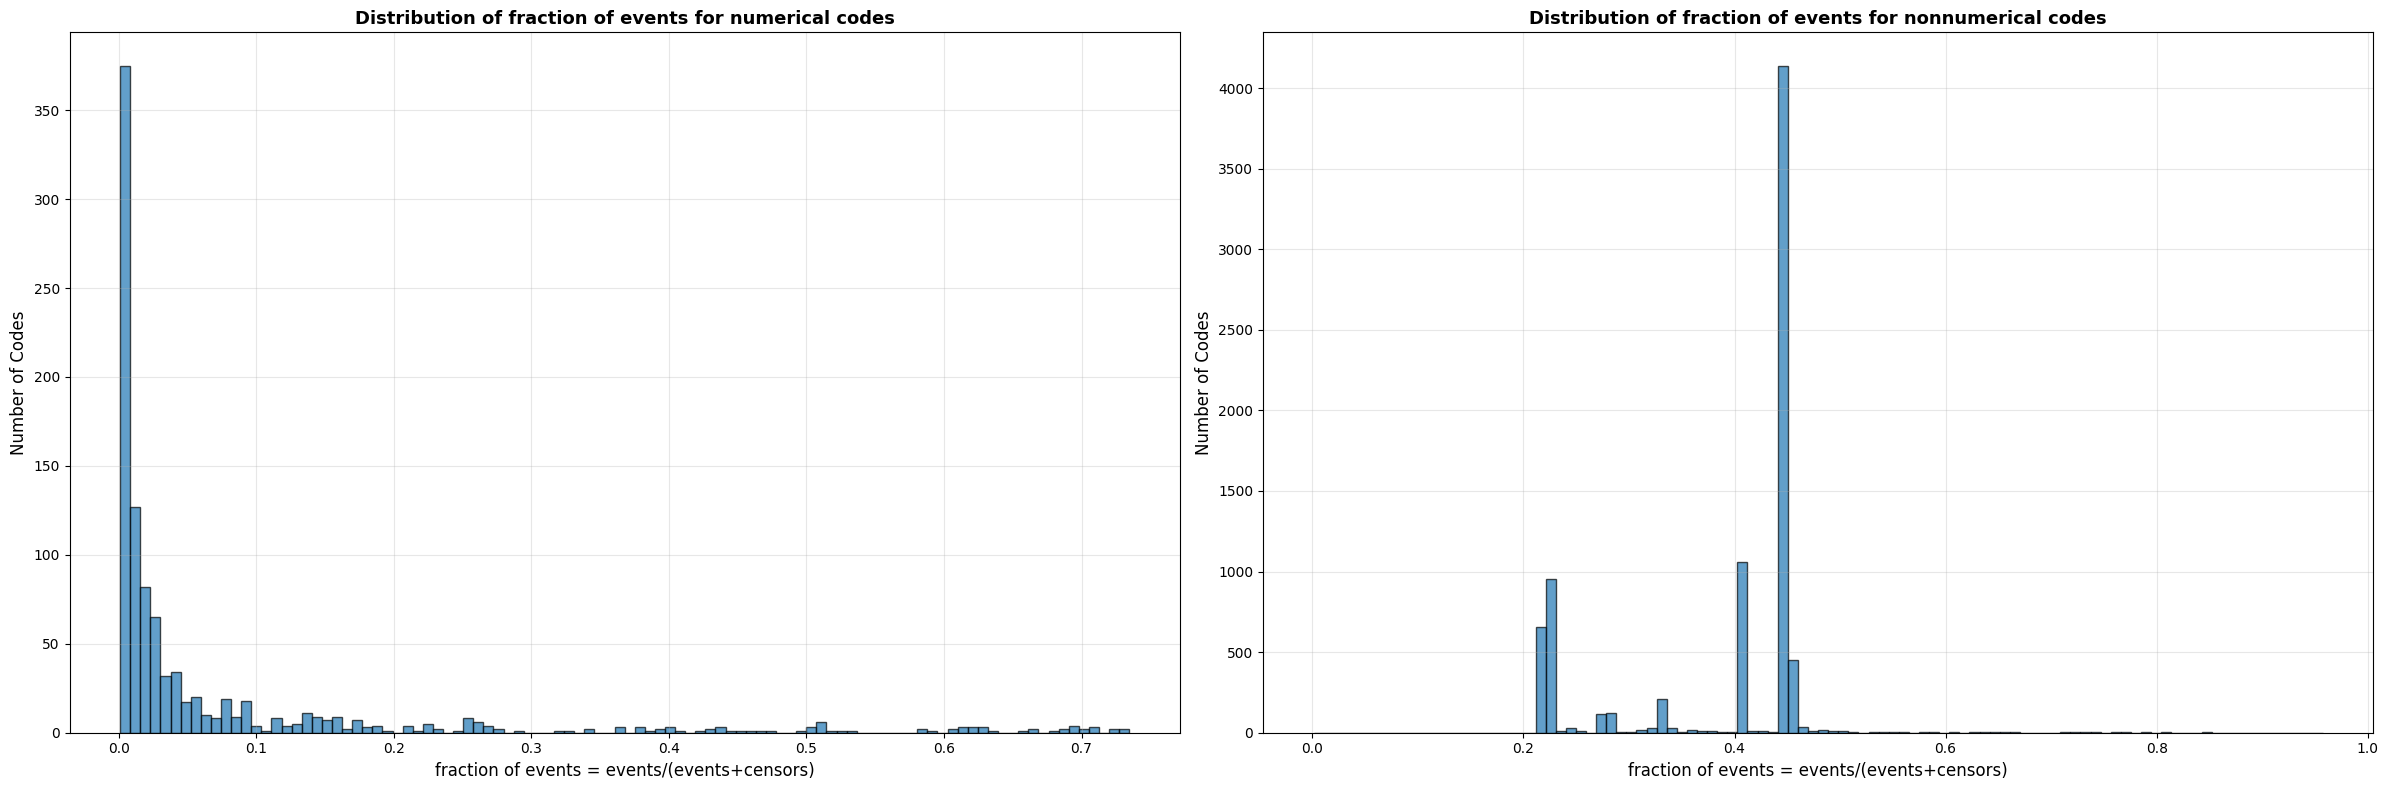

In [13]:
# 7175280
import matplotlib.pyplot as plt
non_numerical_ratio = []
numerical_ratio = []
numerical_codes = list(mtpp_task.numerical_task_to_index_map.keys())
print(numerical_codes)
for i in mtpp_task.pretraining_task_info:
    if i[0] in numerical_codes:
        numerical_ratio.append((i[3]/(i[2]+i[3])))
    else:
        non_numerical_ratio.append((i[3]/(i[2]+i[3])))
    # print(i[0],i[3]/(i[2]+i[3]),i[2]+i[3])

fig, axes = plt.subplots(1, 2, figsize=(24, 8))

# Plot 1: Distribution of non-missingness ratios
axes[0].hist(numerical_ratio, bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('fraction of events = events/(events+censors)', fontsize=12)
axes[0].set_ylabel('Number of Codes', fontsize=12)
axes[0].set_title('Distribution of fraction of events for numerical codes', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Distribution of code frequencies

axes[1].hist(non_numerical_ratio, bins=100, edgecolor='black', alpha=0.7)
axes[1].set_xlabel('fraction of events = events/(events+censors)', fontsize=12)
axes[1].set_ylabel('Number of Codes', fontsize=12)
axes[1].set_title('Distribution of fraction of events for nonnumerical codes', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)


# Create histogram


plt.tight_layout()
plt.savefig('numeric_codes_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
import pickle
ontology_path = "/data2/processed_datasets/zj2398/femr/ontology.pkl"
tokenizer_path = "/data2/processed_datasets/zj2398/femr/cumc_0.1/mtpp/tokenizer"
task_path = "/data2/processed_datasets/zj2398/femr/cumc_0.1/mtpp/mtpp_task.pkl"
with open(ontology_path, 'rb') as f:
    ontology = pickle.load(f)
# with open(task_path, 'rb') as f:
#     task = pickle.load(f)
# tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
mtpp_32k_tokenizer_path= "/data2/processed_datasets/zj2398/femr/cumc_0.1/mtpp_vocab_32k/tokenizer"
mtpp_32k_tokenizer = HierarchicalTokenizer.from_pretrained(mtpp_32k_tokenizer_path, ontology=ontology)
print(len(mtpp_32k_tokenizer.dictionary["vocab"]))
code_list = []
for i in mtpp_32k_tokenizer.dictionary["vocab"]:
    if i['type'] == "code":
        code_list.append(i)
print(len(code_list))

/data/anaconda3/envs/motor_chao/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
import pickle
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
ontology_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/ontology.pkl"
tokenizer_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/tokenizer"
with open(ontology_path, 'rb') as f:
    ontology = pickle.load(f)
motor_tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
code_list = []
for i in motor_tokenizer.dictionary["vocab"]:
    if i['type'] == "code":
        code_list.append(i["code_string"])
print(len(code_list),code_list)

7532 ['MEDS_BIRTH', 'CPT4/1002795', 'Gender/F', 'Gender/M', 'Visit/OP', 'SNOMED/71388002', 'PCORNet/Generic-NI', 'Race/Unknown', 'Visit/OMOP4822459', 'RxNorm/1151131', 'ATC/A', 'LOINC/786-4//UCUM/g/dL', 'LOINC/718-7//UCUM/g/dL', 'ATC/C', 'ATC/B', 'ATC/G', 'LOINC/8462-4//UCUM/mm[Hg]', 'LOINC/8480-6//UCUM/mm[Hg]', 'ATC/J', 'ATC/S', 'RxNorm/1151133', 'ATC/N', 'LOINC/787-2//UCUM/fL', 'LOINC/785-6//UCUM/pg', 'LOINC/788-0//UCUM/%', 'ATC/D', 'ATC/R', 'LOINC/6690-2//UCUM/10*9/L', 'ATC/M', 'LOINC/2345-7//UCUM/mg/dL', 'Ethnicity/Unknown', 'LOINC/2160-0//UCUM/mg/dL', 'LOINC/2951-2//UCUM/mmol/L', 'LOINC/2823-3//UCUM/mmol/L', 'LOINC/789-8//UCUM/10*12/L', 'SNOMED/404684003', 'LOINC/29463-7//UCUM/[oz_av]', 'LOINC/3094-0//UCUM/mg/dL', 'LOINC/8867-4//UCUM//min', 'LOINC/20570-8//UCUM/%', 'RxNorm/1151126', 'LOINC/2075-0//UCUM/mmol/L', 'LOINC/17861-6//UCUM/mg/dL', 'LOINC/706-2//UCUM/%', 'LOINC/8302-2//UCUM/[in_us]', 'LOINC/2028-9//UCUM/mmol/L', 'ATC/P', 'LOINC/8310-5//UCUM/[degF]', 'LOINC/63503-7', 'Visit

tokenizer vocab: 116k
numerical 3k ->719

for 3k numerical codes. both 10% and whole dataset.
(1) ratio of missingness  (2) nonmissing value count

after filtering 0.001 lLOINC: 1994 (715). Snowmed 2651 (4).  


In [19]:
freq = {}
loinc_list = []
snowmed_list = []
for i in code_list:
    # print(i)
    code_type = i["code_string"].split("/")[0]
    if code_type == "LOINC":
        loinc_list.append(i["code_string"])
    elif code_type == "SNOMED":
        snowmed_list.append(i["code_string"])
    freq[code_type] = freq.get(code_type,0) + 1
freq = sorted(freq.items(),key=lambda k:k[1])
for key,value in freq:
    print(key,value)
# print(freq)

[('MEDS_BIRTH', 1), ('PCORNet', 1), ('Domain', 1), ('CMS Place of Service', 1), ('NUCC', 1), ('OMOP Extension', 1), ('MEDS_DEATH', 1), ('HCPCS', 1), ('Gender', 2), ('Ethnicity', 3), ('Race', 4), ('CVX', 4), ('ICD10PCS', 5), ('ICD10CM', 5), ('Visit', 6), ('HemOnc', 10), ('RxNorm', 11), ('CPT4', 12), ('ATC', 116), ('SNOMED', 142), ('LOINC', 318), ('SPL', 15157)]
'''
{'type': 'code', 'code_string': 'MEDS_BIRTH', 'weight': -0.6931471805599453}
{'type': 'code', 'code_string': 'CPT4/1002795', 'weight': -0.6931247327238508}
{'type': 'code', 'code_string': 'LOINC/LP432695-7', 'weight': -0.6867095003616869}
{'type': 'code', 'code_string': 'Gender/F', 'weight': -0.6865629448273971}
{'type': 'code', 'code_string': 'Gender/M', 'weight': -0.6859586499130201}
dict_items: [(key,value),(key,value),(key,value)..,(key,value)]
'''

MEDS_BIRTH 1
PCORNet 1
Domain 1
MEDS_DEATH 1
ICD9Proc 1
Cancer Modifier 1
Medicare Specialty 1
PPI 2
Gender 3
Ethnicity 3
RxNorm Extension 3
OMOP Extension 6
Visit 7
Race 7
CMS Place of Service 7
NUCC 8
NDC 8
ISBT Attribute 10
HCPCS 19
HemOnc 26
ICD9CM 32
CVX 67
ICD10PCS 103
CPT4 365
ICD10CM 714
RxNorm 825
ATC 1571
LOINC 1994
SNOMED 2651
SPL 107765


"\n{'type': 'code', 'code_string': 'MEDS_BIRTH', 'weight': -0.6931471805599453}\n{'type': 'code', 'code_string': 'CPT4/1002795', 'weight': -0.6931247327238508}\n{'type': 'code', 'code_string': 'LOINC/LP432695-7', 'weight': -0.6867095003616869}\n{'type': 'code', 'code_string': 'Gender/F', 'weight': -0.6865629448273971}\n{'type': 'code', 'code_string': 'Gender/M', 'weight': -0.6859586499130201}\ndict_items: [(key,value),(key,value),(key,value)..,(key,value)]\n"

In [6]:
import meds_reader
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

meds_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_meds_reader"
# numeric_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader/numeric_value"
database = meds_reader.SubjectDatabase(meds_path)

for subject_id in database:
    subject = database[subject_id]
    for event in subject.events:
        for k,v in event:
            if isinstance(v,str) and v.split("/")[0] == "SPL":
                print(event,k,v)
        # if event.code == "SPL/5d185f23-8af6-4e36-b514-5662986520a5":
        #     print(event)

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/data/anaconda3/envs/motor_chao/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3699, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_2552872/2381449489.py", line None, in <module>
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/data/anaconda3/envs/motor_chao/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 2194, in showtraceback
    stb = self.InteractiveTB.structured_traceback(
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/data/anaconda3/envs/motor_chao/lib/python3.11/site-packages/IPython/core/ultratb.py", line 1182, in structured_traceback
    return FormattedTB.structured_traceback(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/data/anaconda3/envs/motor_chao/lib/python3.11/site-packages/IPython/core/ultratb.py", line 1053, in structured_traceback
    ret

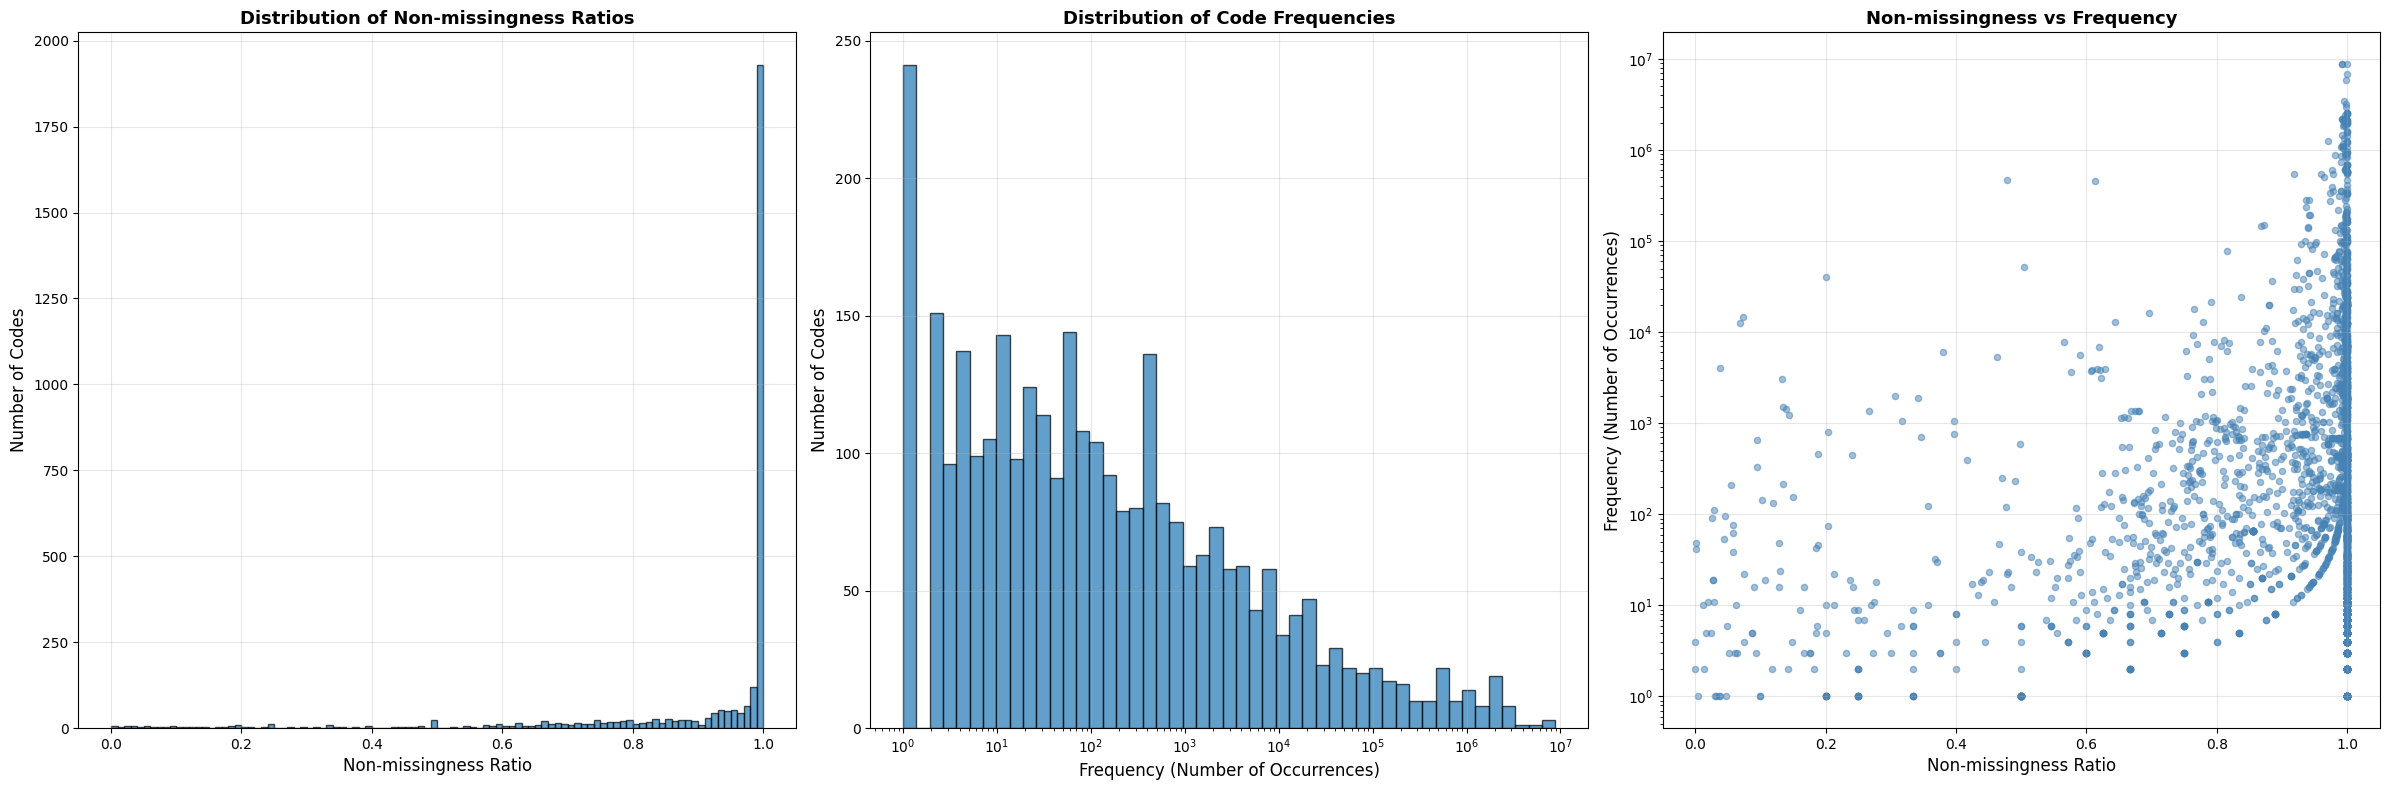

Total codes analyzed: 3090
Mean non-missingness ratio: 0.910
Median non-missingness ratio: 0.999
Mean frequency: 55625
Median frequency: 70


In [2]:
import meds_reader
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

meds_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader"
# numeric_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader/numeric_value"
database = meds_reader.SubjectDatabase(meds_path)
numeric_codes_set = set()

for subject_id in database:
    subject = database[subject_id]
    for event in subject.events:
        if event.numeric_value is not None:
            numeric_codes_set.add(event.code)

import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

# Collect statistics for all codes
code_stats = defaultdict(lambda: {'total': 0, 'numeric': 0})

for subject_id in database:
    subject = database[subject_id]
    for event in subject.events:
        code_stats[event.code]['total'] += 1
        # Check if numeric_value is actually a number (int or float)
        if event.numeric_value is not None and isinstance(event.numeric_value, (int, float)):
            code_stats[event.code]['numeric'] += 1
        elif event.numeric_value is not None and not isinstance(event.numeric_value, (int, float)):
            print(event.code,event.numeric_value)

# Filter to only numeric_codes_set and calculate metrics
nonmissingness_ratios = []
frequencies = []

for code in numeric_codes_set:
    if code in code_stats:
        total = code_stats[code]['total']
        numeric = code_stats[code]['numeric']
        ratio = numeric / total if total > 0 else 0
        
        nonmissingness_ratios.append(ratio)
        frequencies.append(numeric)

# Create the three plots
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

# Plot 1: Distribution of non-missingness ratios
axes[0].hist(nonmissingness_ratios, bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Non-missingness Ratio', fontsize=12)
axes[0].set_ylabel('Number of Codes', fontsize=12)
axes[0].set_title('Distribution of Non-missingness Ratios', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Distribution of code frequencies

# Use logarithmically spaced bins
bins = np.logspace(np.log10(min(frequencies)), np.log10(max(frequencies)), 50)

# Create histogram
axes[1].hist(frequencies, bins=bins, edgecolor='black', alpha=0.7)
# Set both axes to log scale
axes[1].set_xscale('log')
axes[1].set_xlabel('Frequency (Number of Occurrences)', fontsize=12)
axes[1].set_ylabel('Number of Codes', fontsize=12)
axes[1].set_title('Distribution of Code Frequencies', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)
# plt.yscale('log')

# Plot 3: 2D scatter plot
axes[2].scatter(nonmissingness_ratios, frequencies, alpha=0.5, s=20, c='steelblue')
axes[2].set_xlabel('Non-missingness Ratio', fontsize=12)
axes[2].set_ylabel('Frequency (Number of Occurrences)', fontsize=12)
axes[2].set_title('Non-missingness vs Frequency', fontsize=13, fontweight='bold')
axes[2].set_yscale('log')  # Log scale for better visualization
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('numeric_codes_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"Total codes analyzed: {len(numeric_codes_set)}")
print(f"Mean non-missingness ratio: {np.mean(nonmissingness_ratios):.3f}")
print(f"Median non-missingness ratio: {np.median(nonmissingness_ratios):.3f}")
print(f"Mean frequency: {np.mean(frequencies):.0f}")
print(f"Median frequency: {np.median(frequencies):.0f}")

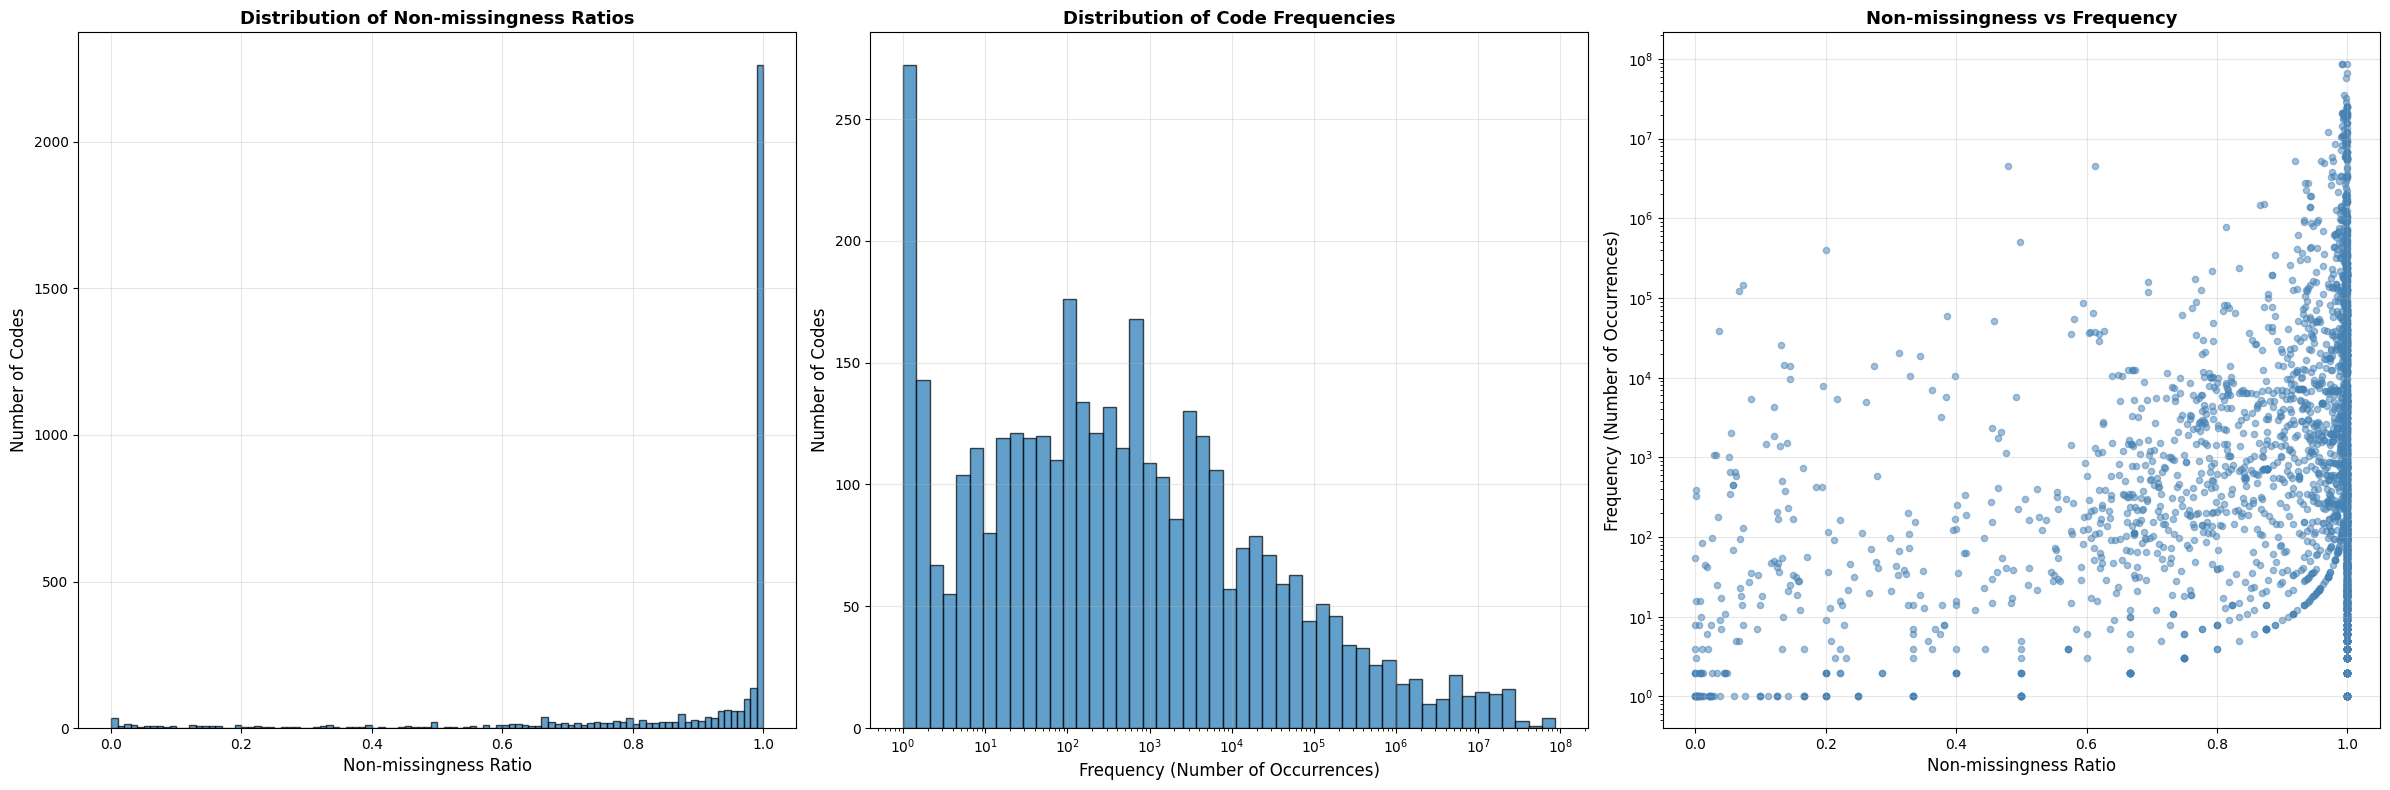

Total codes analyzed: 3738
Mean non-missingness ratio: 0.892
Median non-missingness ratio: 0.998
Mean frequency: 450204
Median frequency: 284


In [3]:
import meds_reader
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

meds_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_meds_reader"
# numeric_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader/numeric_value"
database = meds_reader.SubjectDatabase(meds_path)
numeric_codes_set = set()

for subject_id in database:
    subject = database[subject_id]
    for event in subject.events:
        if event.numeric_value is not None:
            numeric_codes_set.add(event.code)

import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

# Collect statistics for all codes
code_stats = defaultdict(lambda: {'total': 0, 'numeric': 0})

for subject_id in database:
    subject = database[subject_id]
    for event in subject.events:
        code_stats[event.code]['total'] += 1
        # Check if numeric_value is actually a number (int or float)
        if event.numeric_value is not None and isinstance(event.numeric_value, (int, float)):
            code_stats[event.code]['numeric'] += 1
        elif event.numeric_value is not None and not isinstance(event.numeric_value, (int, float)):
            print(event.code,event.numeric_value)

# Filter to only numeric_codes_set and calculate metrics
nonmissingness_ratios = []
frequencies = []

for code in numeric_codes_set:
    if code in code_stats:
        total = code_stats[code]['total']
        numeric = code_stats[code]['numeric']
        ratio = numeric / total if total > 0 else 0
        
        nonmissingness_ratios.append(ratio)
        frequencies.append(numeric)

# Create the three plots
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

# Plot 1: Distribution of non-missingness ratios
axes[0].hist(nonmissingness_ratios, bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Non-missingness Ratio', fontsize=12)
axes[0].set_ylabel('Number of Codes', fontsize=12)
axes[0].set_title('Distribution of Non-missingness Ratios', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Distribution of code frequencies

# Use logarithmically spaced bins
bins = np.logspace(np.log10(min(frequencies)), np.log10(max(frequencies)), 50)

# Create histogram
axes[1].hist(frequencies, bins=bins, edgecolor='black', alpha=0.7)
# Set both axes to log scale
axes[1].set_xscale('log')
axes[1].set_xlabel('Frequency (Number of Occurrences)', fontsize=12)
axes[1].set_ylabel('Number of Codes', fontsize=12)
axes[1].set_title('Distribution of Code Frequencies', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)
# plt.yscale('log')

# Plot 3: 2D scatter plot
axes[2].scatter(nonmissingness_ratios, frequencies, alpha=0.5, s=20, c='steelblue')
axes[2].set_xlabel('Non-missingness Ratio', fontsize=12)
axes[2].set_ylabel('Frequency (Number of Occurrences)', fontsize=12)
axes[2].set_title('Non-missingness vs Frequency', fontsize=13, fontweight='bold')
axes[2].set_yscale('log')  # Log scale for better visualization
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('numeric_codes_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"Total codes analyzed: {len(numeric_codes_set)}")
print(f"Mean non-missingness ratio: {np.mean(nonmissingness_ratios):.3f}")
print(f"Median non-missingness ratio: {np.median(nonmissingness_ratios):.3f}")
print(f"Mean frequency: {np.mean(frequencies):.0f}")
print(f"Median frequency: {np.median(frequencies):.0f}")

In [44]:
print(len(code_stats))
print(len(numeric_codes_set))

# print(list(code_stats.keys())[:10])
# print(code_stats['ICD10CM/R07.90'])

# count = 0
code_list = []
for code_name,value in code_stats.items():
    ratio = value['numeric']/value['total']
    if 100000>value['numeric']>100:
        code_list.append(code_name)
print(len(code_list))

# for code in numeric_codes_set:
#         total = code_stats[code]['total']
#         numeric = code_stats[code]['numeric']
#         ratio = numeric / total if total > 0 else 0
        
#         nonmissingness_ratios.append(ratio)
#         frequencies.append(numeric)

# for code in numeric_codes_set:
#     if code in code_stats:
#         total = code_stats[code]['total']
#         numeric = code_stats[code]['numeric']
#         ratio = numeric / total if total > 0 else 0
        
#         nonmissingness_ratios.append(ratio)
#         frequencies.append(numeric)


83541
3090
1270


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import meds_reader
from collections import defaultdict

from collections import defaultdict
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor
import multiprocessing as mp

def count_codes_for_subjects(args):
    """Process a chunk of subjects and return local code counts"""
    subject_ids_chunk, meds_path = args
    database = meds_reader.SubjectDatabase(meds_path)
    local_stats = defaultdict(int)
    
    for subject_id in subject_ids_chunk:
        subject_num = database[subject_id]
        for event in subject_num.events:
            if (event.numeric_value is not None and 
                isinstance(event.numeric_value, (int, float)) and 
                event.text_value is None):
                local_stats[event.code] += 1
    
    return dict(local_stats)

def calculate_numeric_distribution(meds_path, n_workers=32):    
    # Split subject IDs into chunks
    database = meds_reader.SubjectDatabase(meds_path)
    subject_ids = list(database)
    chunk_size = max(1, len(subject_ids) // n_workers)
    chunks = [subject_ids[i:i + chunk_size] 
              for i in range(0, len(subject_ids), chunk_size)]
    
    # Prepare arguments for each worker
    args_list = [(chunk, meds_path) for chunk in chunks]
    
    # Process chunks in parallel (use ThreadPoolExecutor if database isn't picklable)
    code_stats = defaultdict(int)
    
    # Try ProcessPoolExecutor first (faster for CPU-bound), fallback to ThreadPoolExecutor
    # try:
    with ProcessPoolExecutor(max_workers=n_workers) as executor:
        results = executor.map(count_codes_for_subjects, args_list)
        # results = 
        
        # Merge results
        for local_stats in results:
            for code, count in local_stats.items():
                code_stats[code] += count
    
    # Filter: keep only codes with 100 <= count <= 10^6
    filtered_stats = {code: count for code, count in code_stats.items() 
                      if 400 <= count}
    
    # Sort by frequency (count) in descending order and return only keys
    sorted_codes = [(code,count) for code, count in 
                    sorted(filtered_stats.items(), key=lambda x: x[1], reverse=True)]
    
    # return sorted_codes
    return sorted_codes

# Usage

# def plot_numeric_distribution(database):
#     # Collect statistics for all codes
#     code_stats = defaultdict(lambda: {'total': 0, 'text':0,'numeric': 0,'both':0})

#     for subject_id in database:
#         subject = database[subject_id]
#         for event in subject.events:
#             code_stats[event.code]['total'] += 1
#             # Check if numeric_value is actually a number (int or float)
#             if event.numeric_value is not None and isinstance(event.numeric_value, (int, float)) and event.text_value is None:
#                 code_stats[event.code]['numeric'] += 1
#             elif event.numeric_value is not None and isinstance(event.numeric_value, (int, float)) and event.text_value is not None:
#                 code_stats[event.code]['both'] += 1
#             elif event.numeric_value is  None and event.text_value is not None:
#                 code_stats[event.code]['text'] += 1
#             elif event.numeric_value is not None and not isinstance(event.numeric_value, (int, float)):
#                 print(event.code,event.numeric_value)


#     return code_stats

meds_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader"
result_codes = calculate_numeric_distribution(meds_path, n_workers=32)
print(f"Found {len(result_codes)} codes meeting criteria")
print(result_codes)
# updated_code_stats = plot_numeric_distribution(database)

# 100 - 10000 1053
# 100 - 100000  1279
# 100 - 1000000  1356

Found 1035 codes meeting criteria
[('LOINC/8867-4//UCUM//min', 8816893), ('LOINC/8480-6//UCUM/mm[Hg]', 8761007), ('LOINC/8462-4//UCUM/mm[Hg]', 8756470), ('LOINC/9279-1//UCUM//min', 6837459), ('LOINC/8310-5//UCUM/[degF]', 5932040), ('LOINC/2708-6//UCUM/%', 3484810), ('LOINC/59408-5//UCUM/%', 3201156), ('LOINC/29463-7//UCUM/[oz_av]', 2975739), ('LOINC/60809-1//UCUM/mm[Hg]', 2564645), ('LOINC/8889-8//UCUM/%', 2535955), ('LOINC/76282-3//SNOMED/258983007', 2523786), ('LOINC/89278-6//SNOMED/258983007', 2492105), ('LOINC/60924-8//UCUM/mm[Hg]', 2472487), ('LOINC/718-7//UCUM/g/dL', 2427450), ('LOINC/2951-2//UCUM/mmol/L', 2190569), ('LOINC/2345-7//UCUM/mg/dL', 2178664), ('LOINC/2160-0//UCUM/mg/dL', 2177379), ('LOINC/786-4//UCUM/g/dL', 2172065), ('LOINC/2823-3//UCUM/mmol/L', 2171947), ('LOINC/20102-0//UCUM/cm[H2O]', 2122678), ('LOINC/56869-1//UCUM/mm', 2111797), ('LOINC/3094-0//UCUM/mg/dL', 2066256), ('LOINC/76171-8//SNOMED/258983007', 2059749), ('LOINC/76248-4//UCUM/cm[H2O]', 2027399), ('LOINC/7

In [5]:
import pickle
task_path = "/data2/processed_datasets/zj2398/femr/cumc_0.1/mtpp_vocab_num_1k/mtpp_task.pkl"
with open(task_path, 'rb') as f:
    task = pickle.load(f)
numerical_list = task.numerical_task_to_index_map.keys()
for i in numerical_list:
    print(i,result_codes[i])

LOINC/786-4//UCUM/g/dL 2172065
LOINC/718-7//UCUM/g/dL 2427450
LOINC/8462-4//UCUM/mm[Hg] 8756470
LOINC/8480-6//UCUM/mm[Hg] 8761007
LOINC/787-2//UCUM/fL 1995751
LOINC/785-6//UCUM/pg 1994295
LOINC/788-0//UCUM/% 1982543
LOINC/6690-2//UCUM/10*9/L 1972286
LOINC/2345-7//UCUM/mg/dL 2178664
LOINC/2160-0//UCUM/mg/dL 2177379
LOINC/2951-2//UCUM/mmol/L 2190569
LOINC/2823-3//UCUM/mmol/L 2171947
LOINC/789-8//UCUM/10*12/L 1924910
LOINC/29463-7//UCUM/[oz_av] 2975739
LOINC/3094-0//UCUM/mg/dL 2066256
LOINC/8867-4//UCUM//min 8816893
LOINC/20570-8//UCUM/% 1880314
LOINC/2075-0//UCUM/mmol/L 1863936
LOINC/17861-6//UCUM/mg/dL 1814207
LOINC/8302-2//UCUM/[in_us] 1986471
LOINC/706-2//UCUM/% 913491
LOINC/2028-9//UCUM/mmol/L 1626262
LOINC/8310-5//UCUM/[degF] 5932040
LOINC/39156-5//UCUM/kg/m2 1253240
LOINC/1920-8//UCUM/[iU]/L 1161324
LOINC/5905-5//UCUM/% 828561
LOINC/26515-7//UCUM/10*9/L 1344298
LOINC/28542-9//UCUM/fL 1264461
LOINC/1975-2//UCUM/mg/dL 1114706
LOINC/1742-6//UCUM/[iU]/L 1092004
LOINC/6768-6//UCUM/[iU]/

In [4]:
# mimic
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
import pickle
for task in ["motor","tpp","mtpp"]:
    ontology_path = f"/data2/processed_datasets/zj2398/femr/cumc_0.1/{task}/ontology.pkl"
    tokenizer_path = f"/data2/processed_datasets/zj2398/femr/cumc_0.1/{task}/tokenizer"
    with open(ontology_path, 'rb') as f:
        ontology = pickle.load(f)
    tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
    print(len(tokenizer.dictionary["vocab"]))


8610
8610
8610


In [15]:
for dict_entry in mimic_tokenizer.dictionary["vocab"][:10]:
    print(dict_entry)

{'type': 'numeric', 'property': 'doses_per_24_hrs', 'val_start': -inf, 'val_end': 1.0, 'weight': -1}
{'type': 'numeric', 'property': 'doses_per_24_hrs', 'val_start': 1.0, 'val_end': 2.0, 'weight': -1}
{'type': 'numeric', 'property': 'doses_per_24_hrs', 'val_start': 2.0, 'val_end': inf, 'weight': -1}
{'type': 'numeric', 'property': 'drg_mortality', 'val_start': -inf, 'val_end': inf, 'weight': -1}
{'type': 'numeric', 'property': 'drg_severity', 'val_start': -inf, 'val_end': inf, 'weight': -1}
{'type': 'numeric', 'property': 'emar_seq', 'val_start': -inf, 'val_end': 30.0, 'weight': -1}
{'type': 'numeric', 'property': 'emar_seq', 'val_start': 30.0, 'val_end': 54.0, 'weight': -1}
{'type': 'numeric', 'property': 'emar_seq', 'val_start': 54.0, 'val_end': 82.0, 'weight': -1}
{'type': 'numeric', 'property': 'emar_seq', 'val_start': 82.0, 'val_end': 117.0, 'weight': -1}
{'type': 'numeric', 'property': 'emar_seq', 'val_start': 117.0, 'val_end': 162.0, 'weight': -1}


In [ ]:
mimic_code_list = []
for i in mimic_tokenizer.dictionary["vocab"]:
    if i['type'] == "code":
        mimic_code_list.append(i)
print(len(mimic_code_list))
mimic_freq = {}
for i in mimic_code_list:
    # print(i)
    code_type = i["code_string"].split("/")[0]
    mimic_freq[code_type] = mimic_freq.get(code_type,0) + 1
mimic_freq = sorted(mimic_freq.items(),key=lambda k:k[1])
print(mimic_freq)
'''
[('MEDS_BIRTH', 1), ('ED_OUT', 1), ('ED_REGISTRATION', 1), ('Weight (Lbs)', 1), ('Blood Pressure', 1), ('BMI (kg', 1), ('Height (Inches)', 1), ('SUBJECT_WEIGHT_AT_INFUSION', 1), ('MEDS_DEATH', 1), ('BMI', 1), ('Weight', 1), ('Blood Pressure Sitting', 1), ('Blood Pressure Standing (1 min)', 1), ('Blood Pressure Lying', 1), ('Height', 1)
ood Pressure Standing (3 mins)', 1), ('Blood Pressure Standing', 1), ('GENDER', 2), ('ICU_ADMISSION', 9), ('ICU_DISCHARGE', 9), ('HOSPITAL_DISCHARGE', 13), ('HCPCS', 14), ('HOSPITAL_ADMISSION', 39), ('SUBJECT_FLUID_OUTPUT', 40), ('TRANSFER_TO', 81), ('INFUSION_START', 166), ('INFUSION_END', 166), ('DRG', 445), ('PROCEDURE', 506), ('DIAGNOSIS', 1936), ('LAB', 2130), ('MEDICATION', 2817)]
'''

8390
[('MEDS_BIRTH', 1), ('ED_OUT', 1), ('ED_REGISTRATION', 1), ('Weight (Lbs)', 1), ('Blood Pressure', 1), ('BMI (kg', 1), ('Height (Inches)', 1), ('SUBJECT_WEIGHT_AT_INFUSION', 1), ('MEDS_DEATH', 1), ('BMI', 1), ('Weight', 1), ('Blood Pressure Sitting', 1), ('Blood Pressure Standing (1 min)', 1), ('Blood Pressure Lying', 1), ('Height', 1), ('Blood Pressure Standing (3 mins)', 1), ('Blood Pressure Standing', 1), ('GENDER', 2), ('ICU_ADMISSION', 9), ('ICU_DISCHARGE', 9), ('HOSPITAL_DISCHARGE', 13), ('HCPCS', 14), ('HOSPITAL_ADMISSION', 39), ('SUBJECT_FLUID_OUTPUT', 40), ('TRANSFER_TO', 81), ('INFUSION_START', 166), ('INFUSION_END', 166), ('DRG', 445), ('PROCEDURE', 506), ('DIAGNOSIS', 1936), ('LAB', 2130), ('MEDICATION', 2817)]


In [7]:
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
import pickle
from collections import Counter
from pathlib import Path
ontology_path = "/data2/processed_datasets/zj2398/femr/ontology.pkl"
full_tokenizer_path = "/data/models/zj2398/femr/cumc_full/tpp/tokenizer"

subset_tokenizer_path_zilin = "/data2/processed_datasets/zj2398/femr/cumc_0.1/motor/tokenizer"
subset_ontology_path_zilin = "/data2/processed_datasets/zj2398/femr/cumc_0.1/motor/ontology.pkl"

subset_tokenizer_path_chao = "/data2/processed_datasets/zj2398/femr/cumc_0.1/motor_chao_ontology/tokenizer"
subset_ontology_path_chao = "/data2/processed_datasets/zj2398/femr/cumc_0.1/motor_chao_ontology/ontology.pkl"

full_path_chao = Path("/data2/processed_datasets/zj2398/femr/cumc/motor_chao")

# for tokenizer_path in [subset_token_path,full_token_path]:

def count_type(tokenizer_path,ontology_path):
    with open(ontology_path, 'rb') as f:
        ontology = pickle.load(f)
    vocab_type = Counter()
    tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
    print(tokenizer.dictionary["vocab"][:10])
    for dict_entry in tokenizer.dictionary["vocab"]:
        if dict_entry["type"] == "code":
            code_type = dict_entry["code_string"].split("/")[0]
            vocab_type[code_type] += 1
    # print(vocab_type)
    return vocab_type

zilin_count = count_type(subset_tokenizer_path_zilin,subset_ontology_path_zilin)
chao_count = count_type(subset_tokenizer_path_chao,subset_ontology_path_chao)
chao_full_count = count_type(full_path_chao/"tokenizer",full_path_chao/"ontology.pkl")
print(zilin_count)
print(chao_count)
print(chao_full_count)

[{'type': 'numeric', 'property': 'numeric_value', 'val_start': -inf, 'val_end': -0.4000000059604645, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': -0.4000000059604645, 'val_end': 0.0, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.0, 'val_end': 0.009999999776482582, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.009999999776482582, 'val_end': 0.02388400018960239, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.02388400018960239, 'val_end': 0.029999999329447746, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.029999999329447746, 'val_end': 0.03999999910593033, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.03999999910593033, 'val_end': 0.05000000074505806, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.05000000074505806, 'val_end': 0.07000000029802322, 'weight': -1}, {'

In [4]:
from pathlib import Path
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
import pickle
from collections import Counter

def count_type(tokenizer_path,ontology_path):
    with open(ontology_path, 'rb') as f:
        ontology = pickle.load(f)
    vocab_type = Counter()
    tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
    print(tokenizer.dictionary["vocab"][:10])
    for dict_entry in tokenizer.dictionary["vocab"]:
        if dict_entry["type"] == "code":
            code_type = dict_entry["code_string"].split("/")[0]
            vocab_type[code_type] += 1
    # print(vocab_type)
    return vocab_type
    
allow_loinc_path = Path("/data2/processed_datasets/zj2398/femr/cumc_0.1/motor_allow_loinc")
allow_all_path = Path("/data2/processed_datasets/zj2398/femr/cumc_0.1/motor_allow_all")

allow_loinc_count = count_type(allow_loinc_path/"tokenizer",allow_loinc_path/"ontology.pkl")
allow_all_count = count_type(allow_all_path/"tokenizer",allow_all_path/"ontology.pkl")
print(allow_loinc_count)
print(allow_all_count)

[{'type': 'numeric', 'property': 'numeric_value', 'val_start': -inf, 'val_end': 0.0, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.0, 'val_end': 0.002877000025007883, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.002877000025007883, 'val_end': 0.009999999776482582, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.009999999776482582, 'val_end': 0.019999999552965164, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.019999999552965164, 'val_end': 0.029999999329447746, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.029999999329447746, 'val_end': 0.03999999910593033, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.03999999910593033, 'val_end': 0.05000000074505806, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.05000000074505806, 'val_end': 0.0995200015902519, 'weight': -1},

In [ ]:
# 7944 - zilin_vocab
# 7528 - chao_vocab
# 8668 - allow loinc
# 15930 - allow 15930
# 7532 - chao_full_count

# zilin_vocab = 0
# chao_vocab= 0

def count_vocab(count_obj):
    count = 0
    for i,j in count_obj.items():
        count += j
    return count

# allow_loinc_count = count_vocab(allow_loinc_count)
# allow_all_count = count_vocab(allow_all_count)
# chao_full_count = count_vocab(chao_full_count)
print(chao_full_count)

# for i,j in zilin_count.items():
#     zilin_vocab += j
# print(zilin_vocab)

# for i,j in chao_count.items():
#     chao_vocab += j
# print(chao_vocab)

7532


In [15]:
import pandas as pd
concept_relation_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3/CONCEPT_ANCESTOR.csv"
concept_relation = pd.read_csv(concept_relation_path,sep="\t")
print(concept_relation)

          ancestor_concept_id  descendant_concept_id  \
0                         262                    262   
1                         263                    263   
2                         264                    264   
3                         265                    265   
4                         266                    266   
...                       ...                    ...   
81794853             46369493               46369493   
81794854             46369844               46369844   
81794855             46369845               46369845   
81794856             46369901               46369901   
81794857             46369902               46369902   

          min_levels_of_separation  max_levels_of_separation  
0                                0                         0  
1                                0                         0  
2                                0                         0  
3                                0                         0  
4           

In [ ]:
concept_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3/CONCEPT.csv"
concept = pd.read_csv(concept_path,sep="\t")
print(concept)

/tmp/ipykernel_3265206/2328046253.py:2: DtypeWarning: Columns (5,6,9) have mixed types. Specify dtype option on import or set low_memory=False.
  concept = pd.read_csv(concept_path,sep="\t")


         concept_id                                       concept_name  \
0                 0                                No matching concept   
1                 1                                             Domain   
2                 2                                             Gender   
3                 3                                               Race   
4                 4                                          Ethnicity   
...             ...                                                ...   
7384144    46369940             chloroxylenol .5g/100mL TOPICAL LIQUID   
7384145    46369941    benzalkonium chloride .13g/100mL TOPICAL LIQUID   
7384146    46369942  influenza a virus a/christchurch/16/2010 nib-7...   
7384147    46369943  influenza a virus a/brisbane/10/2010 (h1n1) an...   
7384148    46369944  neem oil, tea tree oil 3[hp_X]/100mL / 5[hp_X]...   

        domain_id vocabulary_id concept_class_id standard_concept  \
0        Metadata           NaN        Und

In [21]:
concept_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3/CONCEPT.csv"

concept = pd.read_csv(
    concept_path,
    sep="\t",  # change to "\t" if your concept file is TSV
    usecols=["concept_id", "vocabulary_id", "concept_code"],
    dtype={"concept_id": "int64", "vocabulary_id": "string", "concept_code": "string"},
)
concept["code"] = concept["vocabulary_id"].astype("string") + "/" + concept["concept_code"].astype("string")
id_to_code = pd.Series(concept["code"].values, index=concept["concept_id"].values)

CHUNKSIZE = 2000000  # tune based on RAM (e.g., 500k, 1M, 2M)


usecols = ["ancestor_concept_id", "descendant_concept_id",
           "min_levels_of_separation", "max_levels_of_separation"]

# concept_relation_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3/CONCEPT_ANCESTOR.csv"
concept_relation = pd.read_csv(concept_relation_path,sep="\t",usecols=usecols,
    dtype={
        "ancestor_concept_id": "int64",
        "descendant_concept_id": "int64",
        "min_levels_of_separation": "int16",
        "max_levels_of_separation": "int16",
    },
    chunksize=CHUNKSIZE,
    )

# reader = pd.read_csv(
#     ancestor_path,
#     sep=ANC_SEP,
#     usecols=usecols,
#     dtype={
#         "ancestor_concept_id": "int64",
#         "descendant_concept_id": "int64",
#         "min_levels_of_separation": "int16",
#         "max_levels_of_separation": "int16",
#     },
#     chunksize=CHUNKSIZE,
# )

out_path = "/data2/processed_datasets/zj2398/femr/ancestor_mapping.csv"
first = True
for chunk in concept_relation:
    # Map IDs -> codes
    anc_code = chunk["ancestor_concept_id"].map(id_to_code)
    des_code = chunk["descendant_concept_id"].map(id_to_code)

    # If any IDs are missing in concept.csv, decide what to do:
    # Option A (recommended): keep original id as string when missing
    chunk["ancestor_concept_id"] = anc_code.fillna(chunk["ancestor_concept_id"].astype("string"))
    chunk["descendant_concept_id"] = des_code.fillna(chunk["descendant_concept_id"].astype("string"))

    # Write incrementally (TSV is typical for large files)
    chunk.to_csv(
        out_path,
        sep="\t",
        index=False,
        mode="w" if first else "a",
        header=first,
    )
    first = False


In [3]:
from collections import Counter
vocab_type = Counter()
for dict_entry in tokenizer.dictionary["vocab"]:
    if dict_entry["type"] == "code":
        code_type = dict_entry["code_string"].split("/")[0]
        vocab_type[code_type] += 1
print(vocab_type)
    

Counter({'SPL': 15162, 'LOINC': 318, 'SNOMED': 142, 'ATC': 113, 'CPT4': 12, 'RxNorm': 11, 'HemOnc': 10, 'Visit': 6, 'ICD10PCS': 5, 'ICD10CM': 5, 'Race': 4, 'CVX': 4, 'Ethnicity': 3, 'Gender': 2, 'MEDS_BIRTH': 1, 'PCORNet': 1, 'Domain': 1, 'CMS Place of Service': 1, 'NUCC': 1, 'OMOP Extension': 1, 'MEDS_DEATH': 1, 'HCPCS': 1})


In [4]:
from pathlib import Path
import pandas as pd
import meds_reader
from multiprocessing import Pool, cpu_count
from functools import partial
from collections import defaultdict

# mimic_split_path = Path("/data/raw_data/mimic/files/mimiciv/meds_v0.6/3.1/MEDS_cohort/metadata")
# meds_reader_path = "/data/raw_data/mimic/files/mimiciv/meds_v0.6/3.1/MEDS_cohort-reader"
mimic_split_path = Path("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform/metadata")
meds_reader_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_meds_reader"

def count_events_for_subjects(subject_ids_with_splits, meds_reader_path):
    """
    Worker function: opens its own database connection and counts events.
    subject_ids_with_splits: list of (subject_id, split_name) tuples
    """
    # Each worker creates its own database connection
    meds_database = meds_reader.SubjectDatabase(meds_reader_path)
    
    split_events = defaultdict(int)
    for subject_id, split_name in subject_ids_with_splits:
        split_events[split_name] += len(meds_database[subject_id].events)
    
    return dict(split_events)


def chunk_list(lst, n_chunks):
    """Split list into n roughly equal chunks."""
    chunk_size = len(lst) // n_chunks + 1
    for i in range(0, len(lst), chunk_size):
        yield lst[i:i + chunk_size]


def main():
    # Load split information
    mimic_split = pd.read_parquet(mimic_split_path / "subject_splits.parquet")
    
    # Create (subject_id, split_name) pairs
    subject_split_pairs = list(zip(mimic_split["subject_id"], mimic_split["split"]))
    
    # Determine number of workers
    n_workers = min(cpu_count(), 32)  # Cap at 32 workers
    print(f"Using {n_workers} workers")
    
    # Split work into chunks
    chunks = list(chunk_list(subject_split_pairs, n_workers))
    
    # Create worker function with fixed meds_reader_path
    worker_fn = partial(count_events_for_subjects, meds_reader_path=meds_reader_path)
    
    # Process in parallel
    with Pool(n_workers) as pool:
        results = pool.map(worker_fn, chunks)
    
    # Aggregate results
    total_events = defaultdict(int)
    for result in results:
        for split_name, count in result.items():
            total_events[split_name] += count
    
    # Print results
    for key, item in total_events.items():
        print(key, item)


if __name__ == "__main__":
    main()

Using 32 workers


train 1562316866
tuning 273247565
held_out 781462164
